# Sugar to feeding: does the Shiu et al. (2024) pathway show up in MaleCNS?

Shiu et al., *Nature* 634, 210–219 (2024) ran a leaky integrate-and-fire model of the female FlyWire
connectome. Driving the labellar **sugar** gustatory receptor neurons (GRNs) of one side made **MN9**
fire. MN9 is the motor neuron behind the proboscis extension that starts feeding. Driving **bitter**
GRNs did not, and bitter added to sugar suppressed MN9. On 100 shuffled connectomes MN9 fired in only 1.

`flybrain` runs a similar model on a different connectome: **MaleCNS v1.0** (a male fly), with its own
neuron model and parameters (`flybrain/brain.py`). This notebook asks whether the same input → output
pathway shows up there, with the default parameters and no tuning (issue #41).

1. **Mapping**: find the sugar GRNs, the bitter GRNs and MN9 in MaleCNS.
2. **Rate sweep**: drive the sugar GRNs at 0–50 Hz, 20 seeds per level, and read MN9.
3. **Controls**: bitter GRNs at the same rates; sugar on a degree-preserving shuffled brain; zero input.
   Also a positive control: drive MN9's strongest excitatory inputs, to show MN9 *can* be driven.
4. **Parameter changes, reported separately**: `sensory_input=False` (because with the default, the
   bitter GRNs already fire at their maximum rate at rest) and `dt=0.005` (to reach the paper's 100–200 Hz).

**Before running:** `pip install flybrain pandas pyarrow matplotlib`. The first `FlyBrain()` downloads the
brain files (~260 MB) to `~/fly-data`. This notebook also downloads two public annotation tables (~46 MB,
cached in `~/fly-data/annotations`). The whole notebook takes about 15–20 minutes on a 10-core laptop CPU.

In [1]:
import hashlib
import os
import platform
import sys
import time
import urllib.request
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numba
import numpy as np
import pandas as pd
import scipy
from scipy import sparse, stats

try:
    import flybrain
except ImportError:  # running from a repository clone without installing
    sys.path.insert(0, str(Path.cwd().parent))
    import flybrain
from flybrain import DATA, FlyBrain

T0 = time.time()
where = "an installed package" if "site-packages" in Path(flybrain.__file__).parts else "the repository clone"
print(f"flybrain {flybrain.__version__} from {where}")
print(f"python {platform.python_version()}, numpy {np.__version__}, scipy {scipy.__version__}, numba {numba.__version__}, "
      f"pandas {pd.__version__}, matplotlib {matplotlib.__version__}")
print(f"{platform.platform()}, {platform.processor() or platform.machine()}, numba threads: {numba.get_num_threads()}")

flybrain 0.1.1 from an installed package
python 3.11.14, numpy 2.4.6, scipy 1.17.1, numba 0.68.1, pandas 3.1.1, matplotlib 3.11.2
macOS-27.2.1-arm64-arm-64bit, arm, numba threads: 10


## 1. Mapping FlyWire names to MaleCNS

What Shiu et al. stimulated and read, from their code
([philshiu/Drosophila_brain_model](https://github.com/philshiu/Drosophila_brain_model), commit `91bdd1e`, `figures.ipynb`):
21 "labellar sugar-sensing GRNs", 21 bitter GRNs and MN9. All are FlyWire IDs from materialization 630.

FlyWire's own cell typing came out after that model. It gives every labellar GRN a morphological type
(`LB1a` ... `LB4b`) and a taste modality ([flyconnectome/flywire_annotations](https://github.com/flyconnectome/flywire_annotations),
`Supplemental_file1_neuron_annotations.tsv`, IDs from materialization 783). MaleCNS v1.0 uses the same type
names. So the chain is: Shiu's ID → FlyWire type (where the ID still exists at 783) → MaleCNS type.

One complication: the prebuilt `brain.npz` stores only one name per neuron, the FlyWire match if MaleCNS
has one, else the MaleCNS type. For the LB3 GRNs, FlyWire matching was done only to the coarse type `LB3`.
So `brain.cells(["LB3"])` returns sugar, water and salt GRNs together. The sugar GRNs are therefore picked
by MaleCNS body ID from the MaleCNS annotation table (column `type`), and mapped onto the brain's neuron
indices through `brain.npz["ids"]`.

In [2]:
ANN = DATA / "annotations"
ANN.mkdir(parents=True, exist_ok=True)
SOURCES = {
    "malecns_annotations.feather": "https://storage.googleapis.com/flyem-male-cns/v1.0/connectome-data/flat-connectome/"
                                   "body-annotations-male-cns-v1.0-minconf-0.5.feather",
    "flywire_annotations.tsv": "https://raw.githubusercontent.com/flyconnectome/flywire_annotations/"
                               "a83b2776d60d5764cef36b927f5f9679c16c47a2/supplemental_files/Supplemental_file1_neuron_annotations.tsv",
}
for name, url in SOURCES.items():
    path = ANN / name
    if not path.exists():
        print(f"downloading {name}")
        urllib.request.urlretrieve(url, path.with_suffix(".part"))
        path.with_suffix(".part").replace(path)
    print(f"{name}: {path.stat().st_size / 1e6:.1f} MB, sha256 {hashlib.sha256(path.read_bytes()).hexdigest()[:16]}...")

malecns_annotations.feather: 14.5 MB, sha256 2177e246113e4cfb...
flywire_annotations.tsv: 31.7 MB, sha256 b214970b55d2fbe0...


In [3]:
# Shiu et al. 2024 inputs and output (FlyWire materialization 630), copied from figures.ipynb at commit 91bdd1e
SHIU_SUGAR = [
    720575940624963786, 720575940630233916, 720575940637568838, 720575940638202345, 720575940617000768,
    720575940630797113, 720575940632889389, 720575940621754367, 720575940621502051, 720575940640649691,
    720575940639332736, 720575940616885538, 720575940639198653, 720575940620900446, 720575940617937543,
    720575940632425919, 720575940633143833, 720575940612670570, 720575940628853239, 720575940629176663,
    720575940611875570]
SHIU_BITTER = [
    720575940621778381, 720575940602353632, 720575940617094208, 720575940619197093, 720575940626287336,
    720575940618600651, 720575940627692048, 720575940630195909, 720575940646212996, 720575940610483162,
    720575940645743412, 720575940627578156, 720575940622298631, 720575940621008895, 720575940629146711,
    720575940610259370, 720575940610481370, 720575940619028208, 720575940614281266, 720575940613061118,
    720575940604027168]
SHIU_MN9 = [720575940660219265, 720575940645521262]   # their 'left' and 'right' MN9

fw = pd.read_csv(ANN / "flywire_annotations.tsv", sep="\t", dtype=str).set_index("root_id")
for name, ids in [("sugar", SHIU_SUGAR), ("bitter", SHIU_BITTER), ("MN9", SHIU_MN9)]:
    ids = [str(i) for i in ids]
    found = [i for i in ids if i in fw.index]
    summary = fw.loc[found].fillna("-").groupby(["cell_type", "cell_sub_class", "side"]).size()
    print(f"Shiu {name}: {len(ids)} IDs, {len(found)} still exist at FlyWire 783 "
          f"(missing: {[i for i in ids if i not in fw.index]})")
    print("   " + "; ".join(f"{t} ({m}, {s}): {k}" for (t, m, s), k in summary.items()))

labellar = fw[fw.cell_type.fillna("").str.match(r"^LB\d") & fw.cell_class.eq("gustatory")]
print("\nFlyWire modality of each labellar GRN type (neurons per side):")
print(labellar.fillna("-").groupby(["cell_type", "cell_sub_class", "side"]).size().unstack(fill_value=0).to_string())

Shiu sugar: 21 IDs, 20 still exist at FlyWire 783 (missing: ['720575940620900446'])
   LB3b (sugar/low_salt, left): 2; LB3c (sugar, left): 9; LB3d (high_salt/heavy_metal, left): 5; LB4b (putative_attractive, left): 4
Shiu bitter: 21 IDs, 20 still exist at FlyWire 783 (missing: ['720575940618600651'])
   LB1a (bitter, left): 8; LB1b (bitter, left): 3; LB1c (bitter, left): 4; LB1d (bitter, left): 5
Shiu MN9: 2 IDs, 1 still exist at FlyWire 783 (missing: ['720575940645521262'])
   CB0701 (ingestion_motor_neuron, right): 1

FlyWire modality of each labellar GRN type (neurons per side):
side                             left  right
cell_type cell_sub_class                    
LB1a      bitter                    8      8
LB1b      bitter                    3      4
LB1c      bitter                    5      6
LB1d      bitter                    5      3
LB1e      glutamate                11     12
LB2a      putative_aversive         2      2
LB2b      putative_aversive         2      2
LB2c  

In [4]:
brain = FlyBrain(device="cpu", seed=0)   # all defaults
ids = np.load(DATA / "brain.npz")["ids"]
print(f"{brain.n:,} neurons, {len(brain.indices):,} connections, dt = {brain.dt * 1000:.0f} ms")

mc = pd.read_feather(ANN / "malecns_annotations.feather")
mc = mc[mc.bodyId.isin(ids)].set_index("bodyId").reindex(ids)
assert (mc.index.to_numpy() == ids).all()
mc_type = mc["type"].fillna("").to_numpy().astype(str)


def by_type(types, side=None):
    # brain indices whose MaleCNS `type` is in `types` (side from brain.side, as brain.cells uses)
    mask = np.isin(mc_type, types)
    if side:
        mask &= brain.side == side
    return np.flatnonzero(mask)


SUGAR_TYPES = ["LB3b", "LB3c"]                  # FlyWire: 'sugar/low_salt', 'sugar'
BITTER_TYPES = ["LB1a", "LB1b", "LB1c", "LB1d"]  # FlyWire: 'bitter'
SHIU_SET_TYPES = ["LB3b", "LB3c", "LB3d", "LB4b"]  # the types Shiu's 'sugar' list actually contains

sugar = {s: by_type(SUGAR_TYPES, s) for s in "LR"}
bitter = {s: brain.cells(["LB1a,LB1d", "LB1b", "LB1c"], side=s) for s in "LR"}   # brain.cells works for bitter
assert all(set(bitter[s]) == set(by_type(BITTER_TYPES, s)) for s in "LR")
shiu_set = {s: by_type(SHIU_SET_TYPES, s) for s in "LR"}
mn9 = {s: brain.cells(["CB0701"], side=s) for s in "LR"}   # MaleCNS type MN9, FlyWire match CB0701
assert all(set(mn9[s]) == set(by_type(["MN9"], s)) for s in "LR")

rows = []
for group, types in [("sugar GRNs (Gr5a)", SUGAR_TYPES), ("bitter GRNs (Gr66a)", BITTER_TYPES),
                     ("other LB3 / LB4b GRNs in Shiu's sugar list", ["LB3d", "LB4b"]), ("MN9", ["MN9"])]:
    for t in types:
        idx = by_type([t])
        rows.append({"Shiu et al. group": group, "MaleCNS type": t, "brain.cell_type (what brain.cells sees)":
                     ", ".join(sorted(set(brain.cell_type[idx]))),
                     "L": int((brain.side[idx] == "L").sum()), "R": int((brain.side[idx] == "R").sum())})
mapping = pd.DataFrame(rows)
print(mapping.to_string(index=False))
print(f"\nbrain.cells(['LB3']) returns {len(brain.cells(['LB3']))} neurons of MaleCNS types "
      f"{sorted(set(mc_type[brain.cells(['LB3'])]))}")
print({k: {s: len(v[s]) for s in 'LR'} for k, v in [('sugar', sugar), ('bitter', bitter), ('shiu_set', shiu_set), ('mn9', mn9)]})
print("MN9 brain indices:", {s: mn9[s].tolist() for s in "LR"}, "body IDs:", {s: ids[mn9[s]].tolist() for s in "LR"})

166,700 neurons, 25,582,938 connections, dt = 20 ms
                         Shiu et al. group MaleCNS type brain.cell_type (what brain.cells sees)  L  R
                         sugar GRNs (Gr5a)         LB3b                                     LB3  5  6
                         sugar GRNs (Gr5a)         LB3c                                     LB3 12 11
                       bitter GRNs (Gr66a)         LB1a                               LB1a,LB1d  6  5
                       bitter GRNs (Gr66a)         LB1b                                    LB1b  3  3
                       bitter GRNs (Gr66a)         LB1c                                    LB1c  9  7
                       bitter GRNs (Gr66a)         LB1d                               LB1a,LB1d  1  4
other LB3 / LB4b GRNs in Shiu's sugar list         LB3d                                     LB3 11 15
other LB3 / LB4b GRNs in Shiu's sugar list         LB4b                                     LB3  4  4
                              

## 2. Stimulus and readout

* **Input as a rate.** Shiu et al. gave each GRN Poisson input that makes it fire at a set rate. Here, at each
  20 ms step, each stimulated GRN independently gets `inject` of +5 V with probability `rate × dt`. Threshold
  is 1 V, so +5 V forces a spike even against inhibition. `dt = 20 ms` caps a neuron at one spike per step,
  so the default model tops out at **50 Hz** (a spike every step). The levels are 0, 5, 10, 20, 30, 40 and 50 Hz.
  The random draws come from `default_rng([41, seed])` and are the same at every level, so a higher rate's
  input spikes are a superset of a lower rate's.
* **Trial.** `brain.reset(seed)`, 0.5 s with no input (the network settles), then 1 s with input. As in the
  paper, the readout is MN9's spike count over that 1 s, which equals its rate in Hz. 20 seeds (0–19) per level.
* **Which MN9.** The GRNs are on the left. The paper reports the MN9 *contralateral* to the stimulated GRNs, so
  the right MN9 is the main readout. The ipsilateral (left) MN9 is reported too.
* **Baseline.** Level 0 is zero input, the same for every input group on a given brain. The noise is matched:
  seed *k* at any rate starts from the same noise stream as seed *k* at 0 Hz. So each run also has a paired
  "extra MN9 spikes" value: its count minus the count in the 0 Hz run with the same seed.

In [5]:
RATES = [0, 5, 10, 20, 30, 40, 50]
N_SEEDS = int(os.environ.get("SUGAR_SEEDS", 20))
SEEDS = list(range(N_SEEDS))
KICK = 5.0
WARM_S, WIN_S = 0.5, 1.0


def trial(b, cells, rate, seed, counts=False):
    # One run. Returns (MN9 L spikes, MN9 R spikes, mean rate of the stimulated cells in Hz, per-neuron counts or None)
    b.reset(seed)
    rng = np.random.default_rng([41, seed])
    warm, win = round(WARM_S / b.dt), round(WIN_S / b.dt)
    p = rate * b.dt
    mn = {"L": 0, "R": 0}
    stim_spikes = 0
    per_neuron = np.zeros(b.n, np.int32) if counts else None
    for t in range(warm + win):
        inject = ()
        if t >= warm and len(cells):
            u = rng.random(len(cells))
            if p > 0:
                inject = [(cells[u < p], KICK)]
        fired = b.step(inject=inject)
        if t >= warm:
            for s in "LR":
                mn[s] += int(np.isin(mn9[s], fired).sum())
            if len(cells):
                stim_spikes += int(np.isin(cells, fired).sum())
            if counts:
                per_neuron[fired] += 1
    return mn["L"], mn["R"], stim_spikes / max(len(cells), 1) / WIN_S, per_neuron


def sweep(b, cells, label, rates=RATES, seeds=SEEDS, baseline=None, contra="R", keep_counts_at=()):
    # Runs every rate x seed. Level 0 is taken from `baseline` (a previous sweep on the same brain) if given.
    # `contra` is the MN9 on the other side from the stimulated cells (the paper's readout).
    rows, counts = [], {}
    for rate in rates:
        for seed in seeds:
            if rate == 0 and baseline is not None:
                r = baseline[(baseline.rate == 0) & (baseline.seed == seed)].iloc[0]
                L, R, stim_hz = int(r.mn9_L), int(r.mn9_R), float(r.stim_hz)
            else:
                L, R, stim_hz, pn = trial(b, cells, rate, seed, counts=rate in keep_counts_at)
                if pn is not None:
                    counts[(rate, seed)] = pn
            rows.append({"input": label, "rate": rate, "seed": seed, "mn9_L": L, "mn9_R": R, "stim_hz": stim_hz,
                         "mn9_contra": R if contra == "R" else L, "mn9_ipsi": L if contra == "R" else R})
    df = pd.DataFrame(rows)
    return (df, counts) if keep_counts_at else df

### Before stimulating: what the GRNs do at rest

With the default `sensory_input=True`, sensory neurons keep the synapses they receive. `brain.py` notes this
makes olfactory receptor neurons excite each other into a runaway loop. The cell below measures each GRN
group's rate with no input.

In [6]:
def resting_rates(b, groups, seeds=SEEDS[:5]):
    out = {}
    for name, cells in groups.items():
        hz = []
        for seed in seeds:
            b.reset(seed)
            n = 0
            for t in range(round((WARM_S + WIN_S) / b.dt)):
                fired = b.step()
                if t >= round(WARM_S / b.dt):
                    n += int(np.isin(cells, fired).sum())
            hz.append(n / len(cells) / WIN_S)
        out[name] = f"{np.mean(hz):.1f} Hz"
    return out

GROUPS = {"sugar L": sugar["L"], "bitter L": bitter["L"], "MN9 L": mn9["L"], "MN9 R": mn9["R"]}
print("default brain (sensory_input=True), no input:", resting_rates(brain, GROUPS))

default brain (sensory_input=True), no input: {'sugar L': '3.0 Hz', 'bitter L': '50.0 Hz', 'MN9 L': '1.8 Hz', 'MN9 R': '1.8 Hz'}


## 3. Default brain: sugar, bitter and zero input

In [7]:
t = time.time()
base = sweep(brain, np.array([], np.int64), "zero input", rates=[0])
sug, sug_counts = sweep(brain, sugar["L"], "sugar L", baseline=base, keep_counts_at=(50,))
bit = sweep(brain, bitter["L"], "bitter L", baseline=base)
print(f"{time.time() - t:.0f} s")


def summary(df):
    # Mean, SD, range of MN9 rate, fraction of runs MN9 fired, and the paired difference from the same seed at 0 Hz
    b0 = df[df.rate == 0].set_index("seed")
    out = []
    for (inp, rate), g in df.groupby(["input", "rate"], sort=False):
        g = g.set_index("seed")
        d = g.mn9_contra - b0.mn9_contra.reindex(g.index)
        di = g.mn9_ipsi - b0.mn9_ipsi.reindex(g.index)
        p = stats.wilcoxon(d, zero_method="zsplit").pvalue if (d != 0).any() else 1.0
        out.append({"input": inp, "rate (Hz)": rate, "stim cells (Hz)": round(g.stim_hz.mean(), 1),
                    "MN9 contra (Hz) mean": round(g.mn9_contra.mean(), 2), "SD": round(g.mn9_contra.std(ddof=1), 2),
                    "min-max": f"{g.mn9_contra.min()}-{g.mn9_contra.max()}",
                    "runs MN9 fired": f"{(g.mn9_contra > 0).mean():.2f}",
                    "extra vs 0 Hz (mean ± SE)": f"{d.mean():+.2f} ± {d.std(ddof=1) / np.sqrt(len(d)):.2f}",
                    "runs above 0 Hz run": f"{(d > 0).mean():.2f}", "Wilcoxon p": float(f"{p:.2g}"),
                    "MN9 ipsi (Hz) mean": round(g.mn9_ipsi.mean(), 2), "ipsi extra": f"{di.mean():+.2f}"})
    return pd.DataFrame(out)


default_runs = pd.concat([sug, bit])
print(summary(sug).to_string(index=False))
print()
print(summary(bit).to_string(index=False))

69 s
  input  rate (Hz)  stim cells (Hz)  MN9 contra (Hz) mean   SD min-max runs MN9 fired extra vs 0 Hz (mean ± SE) runs above 0 Hz run  Wilcoxon p  MN9 ipsi (Hz) mean ipsi extra
sugar L          0              0.0                  2.10 0.79     1-4           1.00              +0.00 ± 0.00                0.00        1.00                1.45      +0.00
sugar L          5              9.1                  1.95 1.00     0-4           0.95              -0.15 ± 0.15                0.15        0.36                1.50      +0.05
sugar L         10             14.5                  1.90 0.91     1-4           1.00              -0.20 ± 0.14                0.10        0.20                1.55      +0.10
sugar L         20             24.8                  1.95 0.94     1-4           1.00              -0.15 ± 0.17                0.20        0.39                1.25      -0.20
sugar L         30             34.0                  2.25 1.12     1-4           1.00              +0.15 ± 0.18         

### Positive control: can anything drive MN9 in this model?

A flat MN9 response could mean the readout simply can't move. So the same rate sweep is applied to MN9's
five strongest excitatory presynaptic partners (picked by weight onto the right MN9). If MN9 responds to
them, MN9 can be driven, and a flat sugar response means the sugar signal doesn't reach it.

In [8]:
W_csr = sparse.csc_matrix((brain.weights, brain.indices, brain.indptr), shape=(brain.n, brain.n)).tocsr()
row = W_csr.getrow(int(mn9["R"][0]))
exc = row.data > 0
order = np.argsort(-row.data[exc])[:5]
pre_mn9 = row.indices[exc][order]
print("top excitatory inputs to MN9 R:", [(brain.cell_type[i], brain.side[i], round(float(w), 3))
                                          for i, w in zip(pre_mn9, row.data[exc][order])])
pos = sweep(brain, pre_mn9, "MN9's top-5 excitatory inputs", baseline=base)
print(summary(pos).to_string(index=False))

top excitatory inputs to MN9 R: [(np.str_('DNge062'), np.str_('L'), 0.056), (np.str_('CB0553'), np.str_('L'), 0.045), (np.str_('CB0493'), np.str_('L'), 0.043), (np.str_('CB0893'), np.str_('L'), 0.04), (np.str_('DNge080'), np.str_('L'), 0.023)]


                        input  rate (Hz)  stim cells (Hz)  MN9 contra (Hz) mean   SD min-max runs MN9 fired extra vs 0 Hz (mean ± SE) runs above 0 Hz run  Wilcoxon p  MN9 ipsi (Hz) mean ipsi extra
MN9's top-5 excitatory inputs          0              0.0                  2.10 0.79     1-4           1.00              +0.00 ± 0.00                0.00    1.000000                1.45      +0.00
MN9's top-5 excitatory inputs          5              5.8                  5.35 0.81     4-7           1.00              +3.25 ± 0.22                1.00    0.000072                2.95      +1.50
MN9's top-5 excitatory inputs         10             10.4                  8.25 1.02    6-10           1.00              +6.15 ± 0.18                1.00    0.000051                4.15      +2.70
MN9's top-5 excitatory inputs         20             20.4                 13.55 1.28   11-16           1.00             +11.45 ± 0.31                1.00    0.000079                6.90      +5.45
MN9's top-5 exc

### Variants of the sugar input on the default brain

* **Shiu's composition.** Shiu's 21 'sugar' GRNs are, by later FlyWire typing, LB3c ×9, LB3b ×2, LB3d ×5 and
  LB4b ×4. Here all left LB3b, LB3c, LB3d and LB4b neurons are driven.
* **Right side.** The right sugar GRNs, read at the left MN9 (contralateral), to check the result isn't one-sided.

In [9]:
shiu = sweep(brain, shiu_set["L"], "LB3b+c+d+LB4b L", baseline=base)
sug_r = sweep(brain, sugar["R"], "sugar R", baseline=base, contra="L")
print(summary(shiu).to_string(index=False))
print()
print(summary(sug_r).to_string(index=False))

          input  rate (Hz)  stim cells (Hz)  MN9 contra (Hz) mean   SD min-max runs MN9 fired extra vs 0 Hz (mean ± SE) runs above 0 Hz run  Wilcoxon p  MN9 ipsi (Hz) mean ipsi extra
LB3b+c+d+LB4b L          0              0.0                  2.10 0.79     1-4           1.00              +0.00 ± 0.00                0.00     1.00000                1.45      +0.00
LB3b+c+d+LB4b L          5              9.2                  1.95 1.00     1-4           1.00              -0.15 ± 0.13                0.10     0.32000                1.45      +0.00
LB3b+c+d+LB4b L         10             15.1                  2.20 1.11     0-4           0.90              +0.10 ± 0.18                0.30     0.42000                1.55      +0.10
LB3b+c+d+LB4b L         20             25.9                  2.35 1.04     0-4           0.95              +0.25 ± 0.14                0.35     0.12000                1.45      +0.00
LB3b+c+d+LB4b L         30             35.0                  2.35 0.67     1-3       

## 4. Control: degree-preserving shuffle

The shuffle is built here from the brain's own weight arrays; `flybrain/` is not edited. Every connection keeps
its postsynaptic neuron and its size. Its presynaptic end is reassigned by one random permutation of all
connections' presynaptic ends (a configuration-model rewiring), and the connection takes the new presynaptic
neuron's sign. So every neuron keeps its in-degree, its out-degree, its sign and the sizes of its inputs, but
the circuit is random. Self-connections are dropped and repeated pairs merged. The shuffled arrays replace
`indptr/indices/weights` on a second `FlyBrain` instance (CPU), so the same `step()` code runs them.

In [10]:
def shuffled_like(b, seed=41):
    n = b.n
    pre = np.repeat(np.arange(n, dtype=np.int64), np.diff(b.indptr))   # CSC: columns are presynaptic
    post = b.indices.astype(np.int64)
    w = b.weights
    sign = np.ones(n, np.float32)
    sign[pre] = np.sign(w)                                             # one sign per presynaptic neuron
    assert (np.sign(w) == sign[pre]).all(), "a neuron has mixed-sign outputs"
    new_pre = np.random.default_rng(seed).permutation(pre)
    keep = new_pre != post
    w_new = np.abs(w[keep]) * sign[new_pre[keep]]
    S = sparse.csc_matrix((w_new, (post[keep], new_pre[keep])), shape=(n, n), dtype=np.float32)
    S.sum_duplicates()
    S.sort_indices()
    info = {"connections before": len(w), "self-loops dropped": int((~keep).sum()),
            "after merging duplicates": int(S.nnz)}
    sb = FlyBrain(device="cpu", seed=0, sensory_input=b.sensory_input)
    sb.indptr, sb.indices, sb.weights = S.indptr, S.indices, S.data
    return sb, info


t = time.time()
shuf_brain, info = shuffled_like(brain)
print(info, f"{time.time() - t:.0f} s")
base_shuf = sweep(shuf_brain, np.array([], np.int64), "zero input (shuffled)", rates=[0])
sug_shuf = sweep(shuf_brain, sugar["L"], "sugar L, shuffled brain", baseline=base_shuf)
print(summary(sug_shuf).to_string(index=False))
del shuf_brain

{'connections before': 25582938, 'self-loops dropped': 389, 'after merging duplicates': 25494871} 2 s


                  input  rate (Hz)  stim cells (Hz)  MN9 contra (Hz) mean   SD min-max runs MN9 fired extra vs 0 Hz (mean ± SE) runs above 0 Hz run  Wilcoxon p  MN9 ipsi (Hz) mean ipsi extra
sugar L, shuffled brain          0              0.0                  8.75 0.72    8-10           1.00              +0.00 ± 0.00                0.00       1.000                5.00      +0.00
sugar L, shuffled brain          5             11.1                  8.95 0.76    7-10           1.00              +0.20 ± 0.17                0.40       0.260                4.95      -0.05
sugar L, shuffled brain         10             14.8                  9.00 0.65    8-10           1.00              +0.25 ± 0.16                0.40       0.150                4.95      -0.05
sugar L, shuffled brain         20             22.8                  9.00 0.79    7-10           1.00              +0.25 ± 0.19                0.30       0.300                4.80      -0.20
sugar L, shuffled brain         30           

## 5. One parameter changed: `sensory_input=False`

With the default, the bitter GRNs fire at their 50 Hz ceiling at rest (section 2), so stimulating them adds
nothing, and bitter is not a usable control. `FlyBrain(sensory_input=False)` is flybrain's own switch for this
(see `brain.py`): it removes the synapses *onto* sensory neurons, so GRNs fire only from noise and what is
injected. Nothing else changes. The section 3–4 numbers above are the "before"; these are the "after".

In [11]:
t = time.time()
brain_ns = FlyBrain(device="cpu", seed=0, sensory_input=False)
print("sensory_input=False, no input:", resting_rates(brain_ns, GROUPS))
base_ns = sweep(brain_ns, np.array([], np.int64), "zero input", rates=[0])
sug_ns = sweep(brain_ns, sugar["L"], "sugar L", baseline=base_ns)
bit_ns = sweep(brain_ns, bitter["L"], "bitter L", baseline=base_ns)
pos_ns = sweep(brain_ns, pre_mn9, "MN9's top-5 excitatory inputs", baseline=base_ns)
shuf_ns, info_ns = shuffled_like(brain_ns)
print(info_ns)
base_shuf_ns = sweep(shuf_ns, np.array([], np.int64), "zero input (shuffled)", rates=[0])
sug_shuf_ns = sweep(shuf_ns, sugar["L"], "sugar L, shuffled brain", baseline=base_shuf_ns)
del shuf_ns
print(f"{time.time() - t:.0f} s")
for df in (sug_ns, bit_ns, pos_ns, sug_shuf_ns):
    print(summary(df).to_string(index=False))
    print()

sensory_input=False, no input: {'sugar L': '0.3 Hz', 'bitter L': '0.2 Hz', 'MN9 L': '2.2 Hz', 'MN9 R': '1.6 Hz'}


{'connections before': 25088107, 'self-loops dropped': 356, 'after merging duplicates': 24999874}


127 s
  input  rate (Hz)  stim cells (Hz)  MN9 contra (Hz) mean   SD min-max runs MN9 fired extra vs 0 Hz (mean ± SE) runs above 0 Hz run  Wilcoxon p  MN9 ipsi (Hz) mean ipsi extra
sugar L          0              0.0                  1.55 0.76     0-3           0.90              +0.00 ± 0.00                0.00    1.000000                1.90      +0.00
sugar L          5              5.0                  1.85 0.75     0-3           0.95              +0.30 ± 0.16                0.35    0.120000                2.10      +0.20
sugar L         10             10.0                  1.95 0.89     0-3           0.90              +0.40 ± 0.15                0.40    0.030000                2.30      +0.40
sugar L         20             20.2                  2.55 0.94     1-4           1.00              +1.00 ± 0.21                0.65    0.000590                2.35      +0.45
sugar L         30             30.3                  2.90 1.17     1-5           1.00              +1.35 ± 0.22        

## 6. One parameter changed: `dt=0.005`

Shiu et al. swept 10–200 Hz and set their one free parameter so that 100 Hz sugar input gives about 80% of
MN9's maximum rate. With 20 ms steps, flybrain can't go above 50 Hz. `FlyBrain(dt=0.005)` uses 5 ms steps
(`tonic` is rescaled automatically, `brain.py`), so GRNs can fire up to 200 Hz. Everything else is default
(`sensory_input=True`). 10 seeds per level, sugar and positive control only.

In [12]:
t = time.time()
brain_dt = FlyBrain(device="cpu", seed=0, dt=0.005)
RATES_DT = [0, 25, 50, 100, 150, 200]
base_dt = sweep(brain_dt, np.array([], np.int64), "zero input", rates=[0], seeds=SEEDS[:10])
sug_dt = sweep(brain_dt, sugar["L"], "sugar L, dt=5 ms", rates=RATES_DT, seeds=SEEDS[:10], baseline=base_dt)
pos_dt = sweep(brain_dt, pre_mn9, "MN9's top-5 inputs, dt=5 ms", rates=RATES_DT, seeds=SEEDS[:10], baseline=base_dt)
del brain_dt
print(f"{time.time() - t:.0f} s")
print(summary(sug_dt).to_string(index=False))
print()
print(summary(pos_dt).to_string(index=False))

115 s
           input  rate (Hz)  stim cells (Hz)  MN9 contra (Hz) mean   SD min-max runs MN9 fired extra vs 0 Hz (mean ± SE) runs above 0 Hz run  Wilcoxon p  MN9 ipsi (Hz) mean ipsi extra
sugar L, dt=5 ms          0              0.0                   3.9 0.57     3-5           1.00              +0.00 ± 0.00                0.00       1.000                 3.1      +0.00
sugar L, dt=5 ms         25             40.0                   4.0 0.47     3-5           1.00              +0.10 ± 0.23                0.30       1.000                 2.7      -0.40
sugar L, dt=5 ms         50             67.8                   4.1 0.74     3-5           1.00              +0.20 ± 0.25                0.20       0.750                 2.5      -0.60
sugar L, dt=5 ms        100            116.1                   4.1 0.32     4-5           1.00              +0.20 ± 0.20                0.30       0.620                 1.7      -1.40
sugar L, dt=5 ms        150            159.9                   4.5 0.53   

                      input  rate (Hz)  stim cells (Hz)  MN9 contra (Hz) mean   SD min-max runs MN9 fired extra vs 0 Hz (mean ± SE) runs above 0 Hz run  Wilcoxon p  MN9 ipsi (Hz) mean ipsi extra
MN9's top-5 inputs, dt=5 ms          0              0.0                   3.9 0.57     3-5           1.00              +0.00 ± 0.00                0.00       1.000                 3.1      +0.00
MN9's top-5 inputs, dt=5 ms         25             26.4                  18.8 1.32   17-21           1.00             +14.90 ± 0.38                1.00       0.002                 9.7      +6.60
MN9's top-5 inputs, dt=5 ms         50             50.7                  31.6 1.17   30-33           1.00             +27.70 ± 0.37                1.00       0.002                15.2     +12.10
MN9's top-5 inputs, dt=5 ms        100            101.1                  56.1 2.23   53-60           1.00             +52.20 ± 0.63                1.00       0.002                26.7     +23.60
MN9's top-5 inputs, dt=5 

## 7. Where does the sugar signal go?

Using the default brain at 50 Hz: neurons whose spike count over the 1 s rises reliably above the matched
0 Hz run. "Reliably" means a mean increase of at least 1 spike, and higher in at least 18 of the 20 seeds.
The stimulated GRNs are excluded. For each such neuron the table gives its hop distance from the sugar GRNs.

In [13]:
base_counts = {}
for seed in SEEDS:
    _, _, _, pn = trial(brain, np.array([], np.int64), 0, seed, counts=True)
    base_counts[seed] = pn
diff = np.array([sug_counts[(50, s)] - base_counts[s] for s in SEEDS], np.float32)
up = (diff.mean(0) >= 1) & ((diff > 0).sum(0) >= int(0.9 * len(SEEDS)))
up[sugar["L"]] = False

# hop distance from the left sugar GRNs (any-sign path)
A = abs(W_csr)
hop = np.full(brain.n, -1)
hop[sugar["L"]] = 0
frontier = np.zeros(brain.n)
frontier[sugar["L"]] = 1
for k in range(1, 6):
    new = ((A @ frontier) > 0) & (hop < 0)
    hop[new] = k
    frontier = new.astype(float)
print(f"{up.sum()} neurons respond reliably to 50 Hz sugar input; MN9 L/R hop distance: {hop[mn9['L']]}, {hop[mn9['R']]}")
print("by hop distance:", dict(zip(*np.unique(hop[up], return_counts=True))))
resp = pd.DataFrame({"type": mc_type[up], "side": brain.side[up], "superclass": brain.superclass[up],
                     "hop": hop[up], "extra spikes": diff.mean(0)[up]})
print(resp.groupby(["type", "side", "superclass", "hop"]).agg(neurons=("extra spikes", "size"),
      mean_extra=("extra spikes", "mean")).sort_values("mean_extra", ascending=False).round(1).head(25).to_string())

116 neurons respond reliably to 50 Hz sugar input; MN9 L/R hop distance: [2], [2]
by hop distance: {np.int64(1): np.int64(76), np.int64(2): np.int64(38), np.int64(3): np.int64(2)}
                                      neurons  mean_extra
type      side superclass        hop                     
GNG215    L    cb_intrinsic      1          1   25.000000
ANXXX462a L    ascending_neuron  1          1   24.799999
          L    cb_sensory        1          1   24.400000
LB2d      L    cb_sensory        1          2   22.600000
LB3d      L    cb_sensory        1          5   21.200001
GNG228    L    cb_intrinsic      1          1   19.400000
GNG038    L    cb_intrinsic      1          1   19.000000
GNG452    L    cb_intrinsic      1          2   17.799999
GNG038    R    cb_intrinsic      1          1   16.500000
GNG232    L    cb_intrinsic      1          1   14.500000
GNG254    L    cb_intrinsic      1          1   14.300000
GNG229    L    cb_intrinsic      1          1   14.200000
GNG042  

## 8. Summary table and plots

In [14]:
everything = pd.concat([
    summary(sug).assign(brain="default"), summary(bit).assign(brain="default"),
    summary(pos).assign(brain="default"), summary(shiu).assign(brain="default"),
    summary(sug_r).assign(brain="default"), summary(sug_shuf).assign(brain="default, shuffled"),
    summary(sug_ns).assign(brain="sensory_input=False"), summary(bit_ns).assign(brain="sensory_input=False"),
    summary(pos_ns).assign(brain="sensory_input=False"),
    summary(sug_shuf_ns).assign(brain="sensory_input=False, shuffled"),
    summary(sug_dt).assign(brain="dt=0.005"), summary(pos_dt).assign(brain="dt=0.005")])
everything = everything[["brain"] + [c for c in everything.columns if c != "brain"]]
everything.to_csv("sugar_feeding_numbers.csv", index=False)
print(f"wrote sugar_feeding_numbers.csv ({len(everything)} rows); "
      f"sha256 {hashlib.sha256(everything.to_csv(index=False).encode()).hexdigest()[:16]}")

wrote sugar_feeding_numbers.csv (82 rows); sha256 359fb182ca72dcea


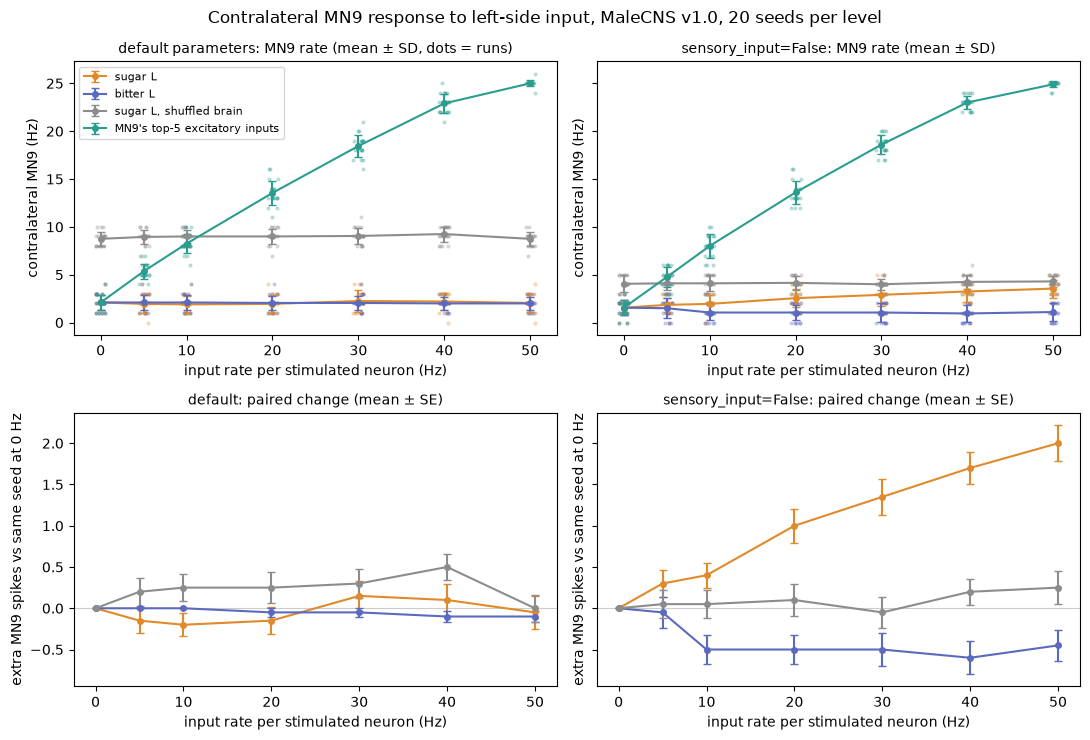

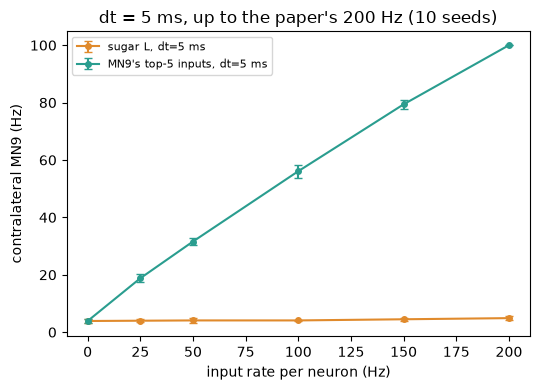

total runtime 8.1 min


In [15]:
COLORS = {"sugar L": "#e08a2c", "bitter L": "#5b6abf", "sugar L, shuffled brain": "0.55",
          "MN9's top-5 excitatory inputs": "#2a9d8f"}


def panel(ax, dfs, title, paired=False):
    for df in dfs:
        label = df.input.iloc[-1]
        color = COLORS.get(label, "k")
        if paired:   # extra MN9 spikes vs the 0 Hz run with the same seed
            b0 = df[df.rate == 0].set_index("seed").mn9_contra
            y = df.mn9_contra.to_numpy() - b0.reindex(df.seed).to_numpy()
        else:
            y = df.mn9_contra.to_numpy()
        g = pd.Series(y).groupby(df.rate.to_numpy())
        m = g.mean()
        err = g.std(ddof=1) / np.sqrt(g.size()) if paired else g.std(ddof=1)
        ax.errorbar(m.index, m, yerr=err, marker="o", ms=4, capsize=3, color=color, label=label)
        if not paired:
            jitter = (np.random.default_rng(0).random(len(df)) - 0.5) * 1.2
            ax.scatter(df.rate + jitter, y, s=4, color=color, alpha=0.25)
    if paired:
        ax.axhline(0, color="0.8", lw=0.8, zorder=0)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("input rate per stimulated neuron (Hz)")
    ax.set_ylabel("extra MN9 spikes vs same seed at 0 Hz" if paired else "contralateral MN9 (Hz)")


fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharey="row")
panel(axes[0, 0], [sug, bit, sug_shuf, pos], "default parameters: MN9 rate (mean ± SD, dots = runs)")
panel(axes[0, 1], [sug_ns, bit_ns, sug_shuf_ns, pos_ns], "sensory_input=False: MN9 rate (mean ± SD)")
panel(axes[1, 0], [sug, bit, sug_shuf], "default: paired change (mean ± SE)", paired=True)
panel(axes[1, 1], [sug_ns, bit_ns, sug_shuf_ns], "sensory_input=False: paired change (mean ± SE)", paired=True)
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Contralateral MN9 response to left-side input, MaleCNS v1.0, {len(SEEDS)} seeds per level")
fig.tight_layout()
fig.savefig("sugar_feeding_mn9.png", dpi=120)
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4))
for df, c in [(sug_dt, "#e08a2c"), (pos_dt, "#2a9d8f")]:
    g = df.groupby("rate").mn9_contra
    ax.errorbar(g.mean().index, g.mean(), yerr=g.std(ddof=1), marker="o", ms=4, capsize=3, color=c, label=df.input.iloc[-1])
ax.set_xlabel("input rate per neuron (Hz)")
ax.set_ylabel("contralateral MN9 (Hz)")
ax.set_title("dt = 5 ms, up to the paper's 200 Hz (10 seeds)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("sugar_feeding_mn9_dt5ms.png", dpi=120)
plt.show()
print(f"total runtime {(time.time() - T0) / 60:.1f} min")

## Conclusions

The numbers quoted here are the ones printed above (20 seeds per level, contralateral MN9, paired change vs the
same seed at 0 Hz, mean ± SE, Wilcoxon signed-rank p).

**With the default parameters, the Shiu et al. result does not appear.**
* Sugar GRNs (LB3b + LB3c, left, 17 neurons) at 5–50 Hz leave the contralateral MN9 at its noise rate,
  about 2 Hz (50 Hz input: −0.05 ± 0.20 spikes, p = 0.80).
* The bitter control can't be tested: the bitter GRNs already fire at the 50 Hz ceiling at rest, because
  sensory neurons excite each other with `sensory_input=True`.
* The shuffled brain shows no sugar effect either (50 Hz: +0.00 ± 0.16).
* The readout works: driving MN9's five strongest excitatory inputs takes it from 2.1 to 25.0 Hz.
* Two variants give small positive effects at 50 Hz: Shiu's mixed GRN set (LB3b+c+d+LB4b, +0.70 ± 0.15,
  p = 0.0009) and right-side sugar read at the left MN9 (+0.55 ± 0.22, p = 0.03).
* With 5 ms steps, which allow the paper's rates, sugar adds +0.2 ± 0.2 spikes at 100 Hz (p = 0.62) and
  +1.0 ± 0.26 at 200 Hz (p = 0.016).

**With `sensory_input=False` (one documented switch, nothing tuned), the paper's pattern appears in direction
but is weak.**
* Sugar raises MN9 in a graded way: +0.40 ± 0.15 at 10 Hz (p = 0.03), +1.00 ± 0.21 at 20 Hz (p = 0.0006),
  +2.00 ± 0.22 at 50 Hz (1.55 → 3.55 Hz; higher than the matched run in 95% of seeds, p = 8e-5).
* Bitter lowers MN9 slightly: −0.45 to −0.60 spikes at 10–50 Hz, p = 0.015–0.04. It does not drive MN9,
  which agrees with the paper.
* On the shuffled brain, sugar does nothing (+0.25 ± 0.20 at 50 Hz, p = 0.25), which also agrees with the paper.
* But the size of the effect is far from the paper's. In Shiu et al. the model was calibrated so that 100 Hz
  sugar input gives about 80% of MN9's maximum rate. Here 50 Hz sugar input adds 2 Hz, while the positive
  control at the same rate adds 23 Hz.

**Where the signal goes.** At 50 Hz (default brain), 116 neurons respond reliably. 76 are one synapse from the
sugar GRNs and 38 are two synapses away. MN9 is two synapses away but is not among them. The sugar signal
reaches the second-order taste neurons in the subesophageal zone (GNG types and the descending neuron DNg67)
and fades before MN9. In this connectome, with this neuron model, the sugar → MN9 path is wired but weak.

**What this does not settle.**
* Shiu et al. tuned their one free parameter on this exact readout; flybrain's parameters were set on
  visual escape and steering.
* The neuron models also differ: flybrain has 20 ms steps, no synaptic delay or time constant,
  per-neuron input normalisation, and tonic drive plus noise.
* One shuffle was used, not 100. The shuffle is degree-preserving, not the paper's.
* "Runs where MN9 fired" is 0.65–1.00 in every condition because MN9 fires from noise at about 2 Hz. The
  paired change is the informative measure.